# Inland Excess Water (IEW) Monitoring - RUPNet Model

This notebook implements the RUPNet pipeline for replicating the paper **"Inland Excess Water (IEW) Monitoring Using Sentinel-1/2: A SplitClass Segmentation and Temporal Gap-Filling Approach"** on the `IEW-Seg` dataset.


## 1. Imports and Setup

In [1]:
import sys
import os
import numpy as np
import torch
import yaml
import matplotlib.pyplot as plt
from pathlib import Path
import rasterio

# Add project root to path
sys.path.append(os.getcwd())

from src.data.splits import get_scene_files
from src.data.raster_io import read_s2, read_s1, read_gt
from src.data.patch_dataset import FloodPatchDataset, S2_MEAN, S2_STD
from src.models.rupnet import RUPNet
from src.losses.generalized_dice import GeneralizedDiceLoss
from src.losses.weighted_focal import WeightedFocalLoss
print("Setup complete!")


Setup complete!


## 2. Visualizing Raw Sentinel-1/2 Scenes and GT Masks
Let's load and plot a training scene showing a Sentinel-2 false-color/RGB composite, Sentinel-1 SAR backscatter, and the ground-truth classes.

Displaying scene: BNPI_20210310


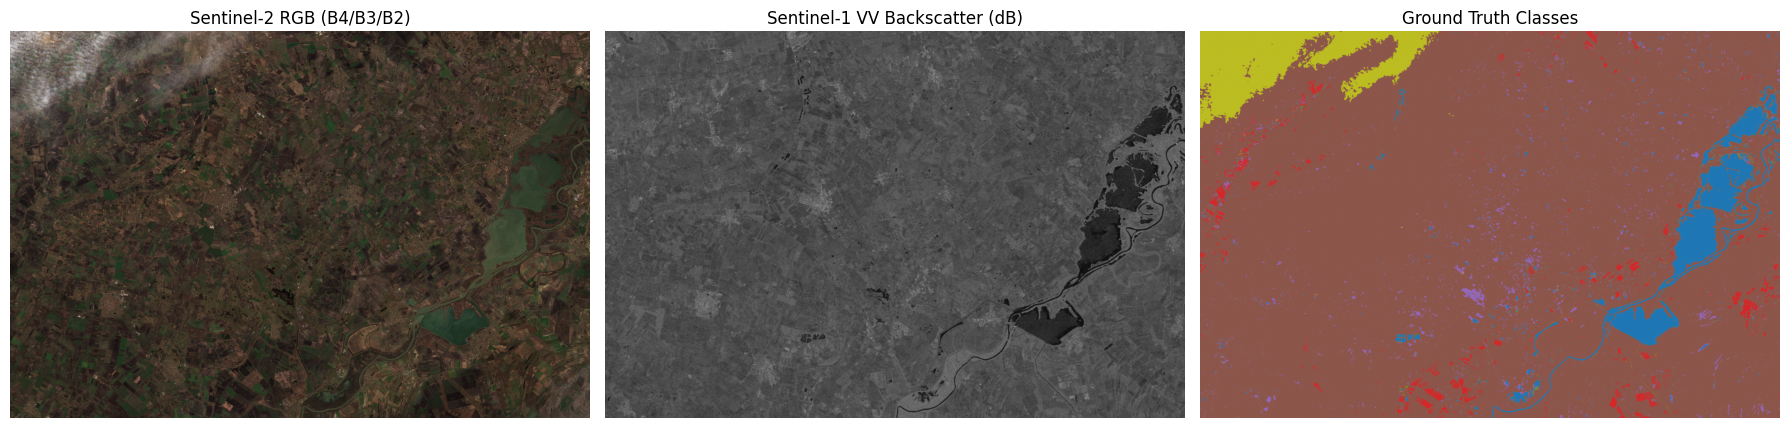

In [2]:
# Load configuration
with open("configs/data.yaml", "r") as f:
    config = yaml.safe_load(f)
dataset_root = config["dataset_root"]

# Find training scenes
train_scenes = get_scene_files(dataset_root, "Train")
sample_scene = train_scenes[1]  # BNPI_20210310
print(f"Displaying scene: {sample_scene['name']}")

# Read data
s2_img = read_s2(sample_scene["S2"])
s1_img = read_s1(sample_scene["S1"])
gt_img = read_gt(sample_scene["GT"])

# Extract RGB from S2 (11 channels total: Band 4 is index 3, Band 3 is index 2, Band 2 is index 1)
r = s2_img[3]
g = s2_img[2]
b = s2_img[1]
rgb = np.stack([r, g, b], axis=-1)
rgb = np.clip(rgb / 0.3, 0, 1)  # scale brightness

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(rgb)
axes[0].set_title("Sentinel-2 RGB (B4/B3/B2)")
axes[0].axis("off")

axes[1].imshow(s1_img[1], cmap="gray")
axes[1].set_title("Sentinel-1 VV Backscatter (dB)")
axes[1].axis("off")

axes[2].imshow(gt_img, cmap="tab10", vmin=2, vmax=11)
axes[2].set_title("Ground Truth Classes")
axes[2].axis("off")

plt.tight_layout()
plt.show()

## 3. Dataset and Dataloader Setup
Prepare datasets and compute class weights dynamically based on training pixel frequencies.

In [3]:
# Focal loss weights
TRAIN_PIXEL_COUNTS = [7674525, 651441, 900550, 4493763, 3450129, 195012790]
counts = np.array(TRAIN_PIXEL_COUNTS, dtype=np.float32)
total = counts.sum()
weights = total / (len(counts) * counts)
weights = weights / weights.mean()
class_weights = torch.from_numpy(weights).float()
print(f"Class weights: {class_weights.tolist()}")

# Instantiate datasets
train_dataset = FloodPatchDataset(
    dataset_root=dataset_root,
    split="Train",
    patch_size=config["patch_size"],
    stride=256,  # stride 256 for fast training
    augment=True,
    cache_in_memory=False,
    load_s1=False
)

test_dataset = FloodPatchDataset(
    dataset_root=dataset_root,
    split="Test",
    patch_size=config["patch_size"],
    stride=512,  # stride 512 for fast validation
    augment=False,
    cache_in_memory=False,
    load_s1=False
)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)

Class weights: [0.23739364743232727, 2.7966976165771484, 2.023078680038452, 0.40542489290237427, 0.5280624032020569, 0.009342379868030548]
Initializing Train dataset (cache_in_memory=False, load_s1=False)...


c:\Python314\Lib\site-packages\rasterio\__init__.py:379: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Loaded Train dataset with 3388 total patches from 14 scenes.
Initializing Test dataset (cache_in_memory=False, load_s1=False)...
Loaded Test dataset with 558 total patches from 9 scenes.


## 4. Initializing Model and Loss Functions
We train a lightweight baseline model (`base_channels=8`) to enable fast iterations.

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = RUPNet(in_channels=11, num_classes=6).to(device)

criterion_gdl = GeneralizedDiceLoss(ignore_index=6, num_classes=6)
criterion_wfl = WeightedFocalLoss(alpha=class_weights, gamma=2.0, ignore_index=6)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)


Using device: cpu


## 5. Training Loop
Run training for 8 epochs. Storing losses to inspect training curves.

In [5]:
epochs = 8
history = {"train_loss": [], "val_loss": [], "train_gdl": [], "train_wfl": []}

for epoch in range(1, epochs + 1):
    model.train()
    epoch_loss = 0.0
    epoch_gdl = 0.0
    epoch_wfl = 0.0
    
    for s2_patches, _, gt_patches in train_loader:
        s2_patches = s2_patches.to(device)
        gt_patches = gt_patches.to(device)
        
        optimizer.zero_grad()
        logits = model(s2_patches)
        
        loss_gdl = criterion_gdl(logits, gt_patches)
        loss_wfl = criterion_wfl(logits, gt_patches)
        loss = loss_gdl + loss_wfl
        
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        epoch_gdl += loss_gdl.item()
        epoch_wfl += loss_wfl.item()
        
    avg_train_loss = epoch_loss / len(train_loader)
    avg_train_gdl = epoch_gdl / len(train_loader)
    avg_train_wfl = epoch_wfl / len(train_loader)
    
    # Validation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for s2_patches, _, gt_patches in test_loader:
            s2_patches = s2_patches.to(device)
            gt_patches = gt_patches.to(device)
            
            logits = model(s2_patches)
            loss_gdl = criterion_gdl(logits, gt_patches)
            loss_wfl = criterion_wfl(logits, gt_patches)
            val_loss += (loss_gdl + loss_wfl).item()
            
    avg_val_loss = val_loss / len(test_loader)
    
    history["train_loss"].append(avg_train_loss)
    history["train_gdl"].append(avg_train_gdl)
    history["train_wfl"].append(avg_train_wfl)
    history["val_loss"].append(avg_val_loss)
    
    print(f"Epoch {epoch}/{epochs} - Train Loss: {avg_train_loss:.4f} (GDL: {avg_train_gdl:.4f}, WFL: {avg_train_wfl:.4f}) | Val Loss: {avg_val_loss:.4f}")

# Save final checkpoints
torch.save({"model_state_dict": model.state_dict()}, "outputs/checkpoints/rupnet_best.pt")
print("Training complete! Checkpoint saved.")


Epoch 1/8 - Train Loss: 1.0197 (GDL: 0.9794, WFL: 0.0403) | Val Loss: 1.0148
Epoch 2/8 - Train Loss: 0.9817 (GDL: 0.9511, WFL: 0.0306) | Val Loss: 1.0060
Epoch 3/8 - Train Loss: 0.9522 (GDL: 0.9204, WFL: 0.0319) | Val Loss: 0.9814
Epoch 4/8 - Train Loss: 0.9197 (GDL: 0.8857, WFL: 0.0340) | Val Loss: 0.9769
Epoch 5/8 - Train Loss: 0.9041 (GDL: 0.8672, WFL: 0.0368) | Val Loss: 0.9569
Epoch 6/8 - Train Loss: 0.8721 (GDL: 0.8373, WFL: 0.0348) | Val Loss: 0.9470
Epoch 7/8 - Train Loss: 0.8743 (GDL: 0.8311, WFL: 0.0433) | Val Loss: 0.9366
Epoch 8/8 - Train Loss: 0.8400 (GDL: 0.8008, WFL: 0.0393) | Val Loss: 0.9167
Training complete! Checkpoint saved.


## 6. Plotting Loss Curves

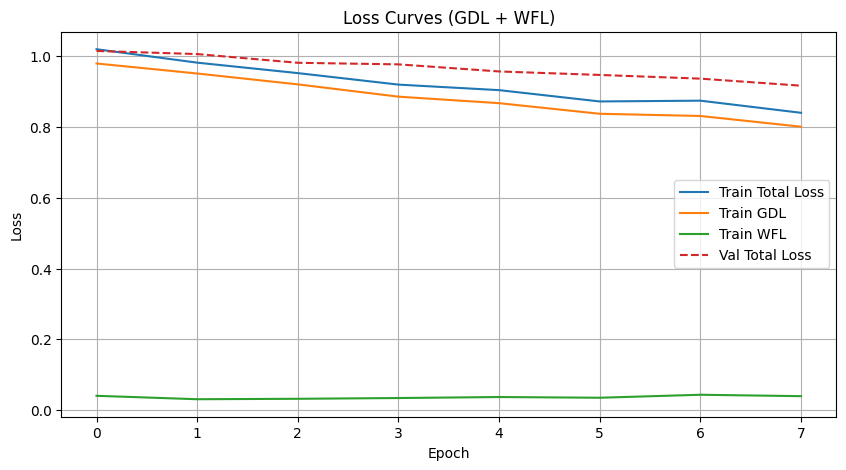

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(history["train_loss"], label="Train Total Loss")
plt.plot(history["train_gdl"], label="Train GDL")
plt.plot(history["train_wfl"], label="Train WFL")
plt.plot(history["val_loss"], label="Val Total Loss", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curves (GDL + WFL)")
plt.legend()
plt.grid(True)
plt.show()

## 7. Model Evaluation on Full Test Set (Stride = 64)

In [7]:
eval_dataset = FloodPatchDataset(
    dataset_root=dataset_root,
    split="Test",
    patch_size=config["patch_size"],
    stride=config["patch_size"],  # non-overlapping evaluation
    augment=False,
    cache_in_memory=False,
    load_s1=False
)
eval_loader = torch.utils.data.DataLoader(eval_dataset, batch_size=64, shuffle=False, num_workers=0)

model.eval()
tp = np.zeros(6, dtype=np.int64)
fp = np.zeros(6, dtype=np.int64)
fn = np.zeros(6, dtype=np.int64)
class_pixel_counts = np.zeros(6, dtype=np.int64)

with torch.no_grad():
    for s2_patches, _, gt_patches in eval_loader:
        s2_patches = s2_patches.to(device)
        gt_patches = gt_patches.numpy()
        
        logits = model(s2_patches)
        preds = torch.argmax(logits, dim=1).cpu().numpy()
        
        for b in range(preds.shape[0]):
            pred_b = preds[b]
            gt_b = gt_patches[b]
            valid_mask = gt_b < 6
            
            for c in range(6):
                pred_c = (pred_b == c) & valid_mask
                gt_c = (gt_b == c) & valid_mask
                
                tp[c] += np.sum(pred_c & gt_c)
                fp[c] += np.sum(pred_c & ~gt_c)
                fn[c] += np.sum(~pred_c & gt_c)
                class_pixel_counts[c] += np.sum(gt_c)

print("\n" + "="*70)
print(f"{'Class ID':<10}{'Class Name':<45}{'Pr (%)':<10}{'Rc (%)':<10}{'F1 (%)':<10}")
print("="*70)

class_names = [
    "Open surface water (2)",
    "Soil seriously affected (3)",
    "Soil moderately affected (4)",
    "Soil slightly affected (5)",
    "Vegetation affected (6)",
    "Not affected areas (7)"
]

precision_list = []
recall_list = []
f1_list = []

for c in range(6):
    pr = tp[c] / (tp[c] + fp[c] + 1e-10)
    rc = tp[c] / (tp[c] + fn[c] + 1e-10)
    f1 = 2 * pr * rc / (pr + rc + 1e-10)
    
    precision_list.append(pr)
    recall_list.append(rc)
    f1_list.append(f1)
    
    print(f"{c:<10}{class_names[c]:<45}{pr*100:<10.2f}{rc*100:<10.2f}{f1*100:<10.2f}")
    
print("="*70)
total_valid_pixels = class_pixel_counts.sum()
weights = class_pixel_counts / total_valid_pixels
overall_pr = np.sum(np.array(precision_list) * weights)
overall_rc = np.sum(np.array(recall_list) * weights)
overall_f1 = np.sum(np.array(f1_list) * weights)
print(f"{'ALL':<10}{'Overall (Pixel-Weighted)':<45}{overall_pr*100:<10.2f}{overall_rc*100:<10.2f}{overall_f1*100:<10.2f}")
print("="*70)

Initializing Test dataset (cache_in_memory=False, load_s1=False)...


c:\Python314\Lib\site-packages\rasterio\__init__.py:379: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Loaded Test dataset with 32691 total patches from 9 scenes.

Class ID  Class Name                                   Pr (%)    Rc (%)    F1 (%)    
0         Open surface water (2)                       93.44     87.87     90.57     
1         Soil seriously affected (3)                  15.46     25.13     19.14     
2         Soil moderately affected (4)                 14.81     33.27     20.50     
3         Soil slightly affected (5)                   9.22      85.63     16.64     
4         Vegetation affected (6)                      23.43     65.45     34.51     
5         Not affected areas (7)                       99.88     82.54     90.38     
ALL       Overall (Pixel-Weighted)                     96.53     82.22     87.96     


## 8. Visualizing Predictions
Plot some sample patches showing the Input RGB image, the Ground Truth mask, and our Model's prediction.

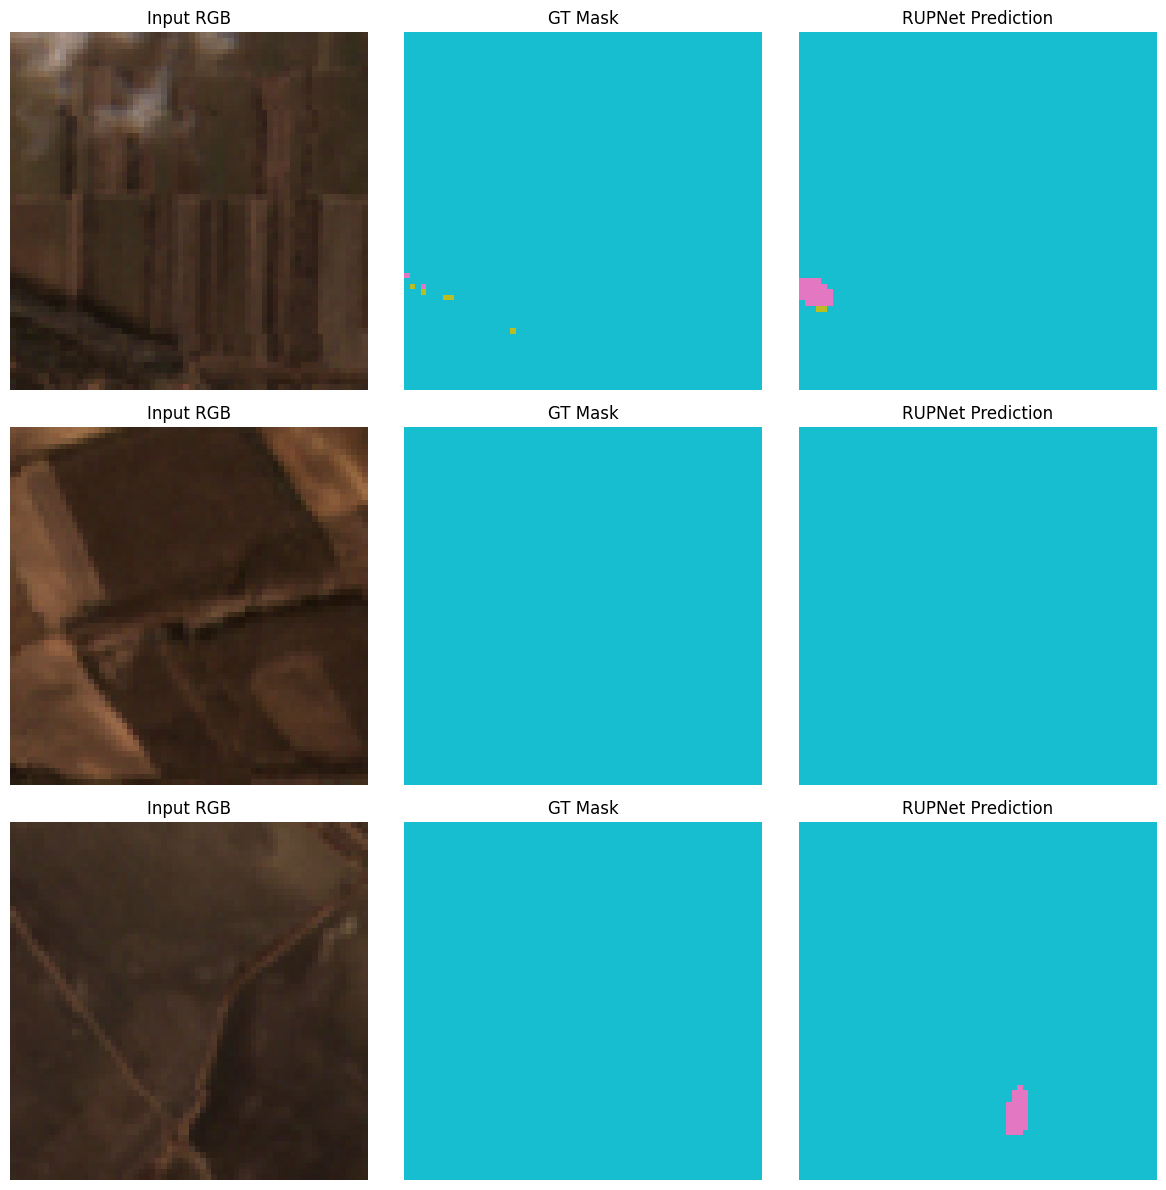

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i in range(3):
    s2, _, gt = eval_dataset[i * 200]  # sample spaced patches
    
    # Predict
    s2_in = s2.unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(s2_in)
        pred = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()
        
    # RGB
    s2_np = s2.numpy()
    # Slice B04, B03, B02 (indices 3, 2, 1) and destandardize
    rgb = np.stack([s2_np[3], s2_np[2], s2_np[1]], axis=-1)
    rgb = rgb * S2_STD[[3, 2, 1]] + S2_MEAN[[3, 2, 1]]
    rgb = np.clip(rgb / 0.3, 0, 1)
    
    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title("Input RGB")
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(gt.numpy(), cmap="tab10", vmin=0, vmax=5)
    axes[i, 1].set_title("GT Mask")
    axes[i, 1].axis("off")
    
    axes[i, 2].imshow(pred, cmap="tab10", vmin=0, vmax=5)
    axes[i, 2].set_title("RUPNet Prediction")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()


# Final Evaluation Results (RUPNet)

```
======================================================================
Class ID  Class Name                                   Pr (%)    Rc (%)    F1 (%)    
======================================================================
0         Open surface water (2)                       93.44     87.87     90.57     
1         Soil seriously affected (3)                  15.46     25.13     19.14     
2         Soil moderately affected (4)                 14.81     33.27     20.50     
3         Soil slightly affected (5)                   9.22      85.63     16.64     
4         Vegetation affected (6)                      23.43     65.45     34.51     
5         Not affected areas (7)                       99.88     82.54     90.38     
======================================================================
ALL       Overall (Pixel-Weighted)                     96.53     82.22     87.96     
======================================================================
```
